### Imports

In [1]:
from tensorflow.keras.preprocessing.image import ImageDataGenerator
from tensorflow.keras.applications import MobileNetV2
from tensorflow.keras import layers, models
from tensorflow.keras.applications.mobilenet_v2 import preprocess_input
import numpy as np
from sklearn.metrics import confusion_matrix
import matplotlib.pyplot as plt
import seaborn as sns
import json
import os

I0000 00:00:1793692007.070319  116542 port.cc:153] oneDNN custom operations are on. You may see slightly different numerical results due to floating-point round-off errors from different computation orders. To turn them off, set the environment variable `TF_ENABLE_ONEDNN_OPTS=0`.
I0000 00:00:1793692007.104881  116542 cpu_feature_guard.cc:227] This TensorFlow binary is optimized to use available CPU instructions in performance-critical operations.
To enable the following instructions: AVX2 AVX_VNNI FMA, in other operations, rebuild TensorFlow with the appropriate compiler flags.
I0000 00:00:1793692007.977265  116542 port.cc:153] oneDNN custom operations are on. You may see slightly different numerical results due to floating-point round-off errors from different computation orders. To turn them off, set the environment variable `TF_ENABLE_ONEDNN_OPTS=0`.


### Inputs

In [2]:
train_dir = "./data/train"
test_dir = "./data/test"
valid_dir = "./data/valid"
os.makedirs("results", exist_ok=True)

### Data Generators

In [3]:
train_datagen = ImageDataGenerator(preprocessing_function=preprocess_input,
                                   rotation_range=20,
                                   width_shift_range=0.1,
                                   height_shift_range=0.1,
                                   horizontal_flip=True)

test_datagen = ImageDataGenerator(preprocessing_function=preprocess_input,)


train_generator = train_datagen.flow_from_directory(train_dir,
                                                    target_size=(224, 224),
                                                    batch_size=32,
                                                    class_mode='categorical',
                                                    shuffle=True)

valid_generator = test_datagen.flow_from_directory(valid_dir,
                                                   target_size=(224, 224),
                                                   batch_size=32,
                                                   class_mode='categorical',
                                                   shuffle=False)

test_generator = test_datagen.flow_from_directory(test_dir,
                                                  target_size=(224, 224),
                                                  batch_size=32,
                                                  class_mode='categorical',
                                                  shuffle=False)

Found 1656 images belonging to 6 classes.
Found 72 images belonging to 6 classes.
Found 72 images belonging to 6 classes.


Clipping input data to the valid range for imshow with RGB data ([0..1] for floats or [0..255] for integers). Got range [-0.5041782..0.46733952].
Clipping input data to the valid range for imshow with RGB data ([0..1] for floats or [0..255] for integers). Got range [-0.7936476..0.10676682].
Clipping input data to the valid range for imshow with RGB data ([0..1] for floats or [0..255] for integers). Got range [-0.3731537..0.77747166].
Clipping input data to the valid range for imshow with RGB data ([0..1] for floats or [0..255] for integers). Got range [-0.39397007..1.0].
Clipping input data to the valid range for imshow with RGB data ([0..1] for floats or [0..255] for integers). Got range [-0.0752511..1.0].
Clipping input data to the valid range for imshow with RGB data ([0..1] for floats or [0..255] for integers). Got range [-0.35241234..1.0].
Clipping input data to the valid range for imshow with RGB data ([0..1] for floats or [0..255] for integers). Got range [-0.8155591..1.0].
Clip

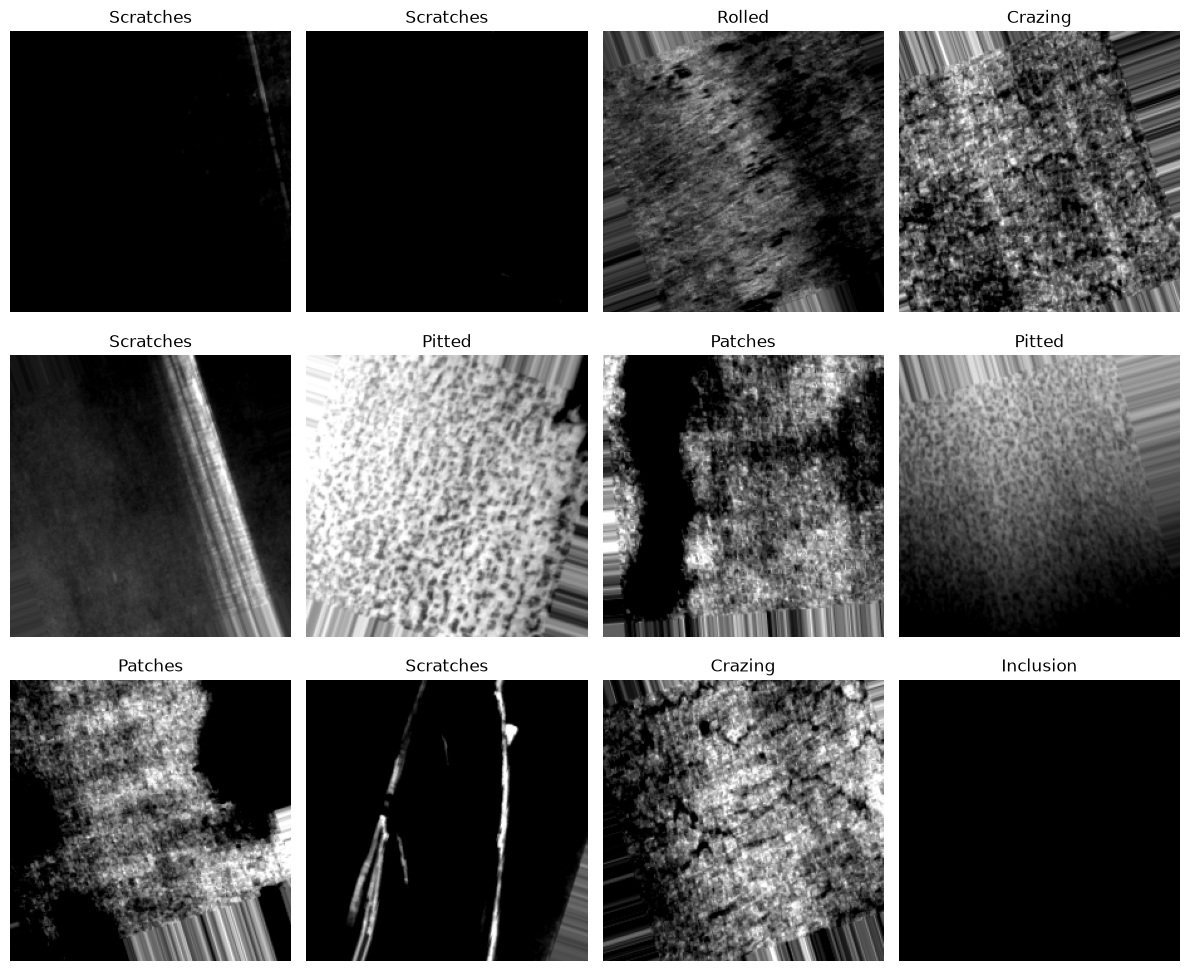

In [4]:
images, labels = next(train_generator)

plt.figure(figsize=(12, 10))

for i in range(12):
    plt.subplot(3, 4, i + 1)

    plt.imshow(images[i])
    class_index = np.argmax(labels[i])
    class_name = list(train_generator.class_indices.keys())[class_index]

    plt.title(class_name)
    plt.axis('off')

plt.tight_layout()
plt.show()

### Model

In [ ]:
base_model = MobileNetV2(input_shape=(224, 224, 3),
                         include_top=False, weights='imagenet')
base_model.trainable = False

model = models.Sequential([
    base_model,
    layers.GlobalAveragePooling2D(),
    layers.Dense(16, activation='relu'),
    layers.Dense(6, activation='softmax')
])

model.compile(optimizer='adam', loss='categorical_crossentropy',
              metrics=['accuracy'])

I0000 00:00:1793692009.671503  116542 gpu_device.cc:2043] Created device /job:localhost/replica:0/task:0/device:GPU:0 with 6292 MB memory:  -> device: 0, name: NVIDIA GeForce RTX 4060 Laptop GPU, pci bus id: 0000:01:00.0, compute capability: 8.9


In [6]:
history = model.fit(train_generator,
                    epochs=10,
                    batch_size=32,
                    validation_data=valid_generator)

Epoch 1/10


I0000 00:00:1793692010.987961  116542 generator_dataset_op.cc:213] Memory patch applied: M_TRIM_THRESHOLD=128 kb was set.
I0000 00:00:1793692012.983479  116701 service.cc:153] XLA service 0x7f5e84034d80 initialized for platform CUDA (this does not guarantee that XLA will be used). Devices:
I0000 00:00:1793692012.983507  116701 service.cc:161]   StreamExecutor [0]: NVIDIA GeForce RTX 4060 Laptop GPU, Compute Capability 8.9 (Driver: 12.4.0; Runtime: 12.9.0; Toolkit: 12.5.0; DNN: 9.27.0)
I0000 00:00:1793692013.039708  116701 dump_mlir_util.cc:269] disabling MLIR crash reproducer, set env var `MLIR_CRASH_REPRODUCER_DIRECTORY` to enable.
I0000 00:00:1793692013.482983  116701 cuda_dnn.cc:461] Loaded cuDNN version 92700
I0000 00:00:1793692013.497662  116701 dot_merger.cc:481] Merging Dots in computation: a_inference_one_step_on_data_7996__.122
E0000 00:00:1793692016.395174  116701 cuda_timer.cc:87] Delay kernel timed out: measured time has sub-optimal accuracy. There may be a missing warmup e

 1/52 ━━━━━━━━━━━━━━━━━━━━ 7:00 8s/step - accuracy: 0.0938 - loss: 2.1198

I0000 00:00:1793692019.194642  116701 device_compiler.h:208] Compiled cluster using XLA!  This line is logged at most once for the lifetime of the process.


11/52 ━━━━━━━━━━━━━━━━━━━━ 5s 142ms/step - accuracy: 0.4688 - loss: 1.4229

I0000 00:00:1793692021.193222  116698 dot_merger.cc:481] Merging Dots in computation: a_inference_one_step_on_data_7996__.122
E0000 00:00:1793692021.654546  116698 cuda_timer.cc:87] Delay kernel timed out: measured time has sub-optimal accuracy. There may be a missing warmup execution, please investigate in Nsight Systems.


52/52 ━━━━━━━━━━━━━━━━━━━━ 0s 241ms/step - accuracy: 0.8424 - loss: 0.5871

E0000 00:00:1793692035.148133  116700 cuda_timer.cc:87] Delay kernel timed out: measured time has sub-optimal accuracy. There may be a missing warmup execution, please investigate in Nsight Systems.


52/52 ━━━━━━━━━━━━━━━━━━━━ 26s 354ms/step - accuracy: 0.8424 - loss: 0.5871 - val_accuracy: 0.8472 - val_loss: 0.5407
Epoch 2/10
52/52 ━━━━━━━━━━━━━━━━━━━━ 8s 150ms/step - accuracy: 0.9873 - loss: 0.0917 - val_accuracy: 0.9167 - val_loss: 0.2757
Epoch 3/10
52/52 ━━━━━━━━━━━━━━━━━━━━ 8s 148ms/step - accuracy: 0.9909 - loss: 0.0531 - val_accuracy: 0.9444 - val_loss: 0.1976
Epoch 4/10
52/52 ━━━━━━━━━━━━━━━━━━━━ 8s 145ms/step - accuracy: 0.9915 - loss: 0.0417 - val_accuracy: 0.9444 - val_loss: 0.1358
Epoch 5/10
52/52 ━━━━━━━━━━━━━━━━━━━━ 8s 145ms/step - accuracy: 0.9958 - loss: 0.0287 - val_accuracy: 0.9722 - val_loss: 0.0815
Epoch 6/10
52/52 ━━━━━━━━━━━━━━━━━━━━ 7s 143ms/step - accuracy: 0.9952 - loss: 0.0239 - val_accuracy: 0.9861 - val_loss: 0.0634
Epoch 7/10
52/52 ━━━━━━━━━━━━━━━━━━━━ 8s 144ms/step - accuracy: 0.9964 - loss: 0.0180 - val_accuracy: 0.9861 - val_loss: 0.0381
Epoch 8/10
52/52 ━━━━━━━━━━━━━━━━━━━━ 7s 142ms/step - accuracy: 0.9982 - loss: 0.0150 - val_accuracy: 0.9861 - val

### Results

In [7]:
def plot_history(history, metric):
    plt.plot(history.history[metric])
    plt.plot(history.history["val_"+metric], "")
    plt.xlabel("Epochs")
    plt.ylabel(metric)
    plt.legend([metric, f"val_{metric}"])
    plt.savefig(
        f"results/{metric}.png",
        dpi=200,
        bbox_inches="tight"
    )
    plt.show()

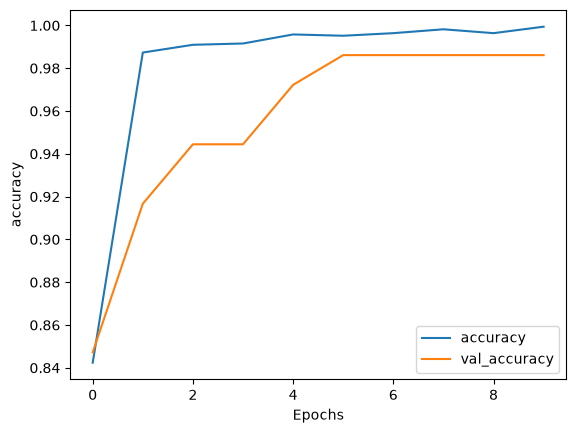

In [8]:
plot_history(history, "accuracy")

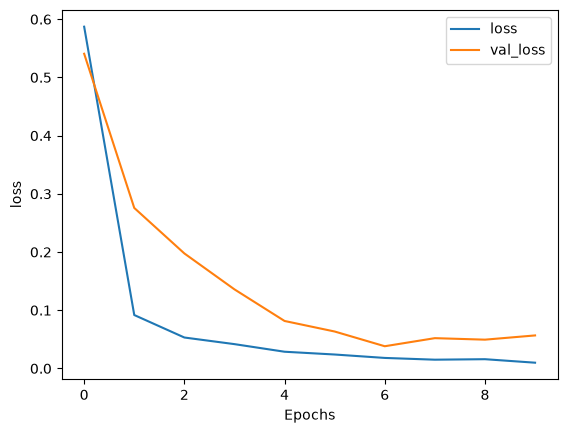

In [9]:
plot_history(history, "loss")

In [10]:
result = model.evaluate(test_generator)
print("Test loss, Test accuracy : ", result)

3/3 ━━━━━━━━━━━━━━━━━━━━ 0s 15ms/step - accuracy: 1.0000 - loss: 0.0228
Test loss, Test accuracy :  [0.022815532982349396, 1.0]


3/3 ━━━━━━━━━━━━━━━━━━━━ 3s 839ms/step


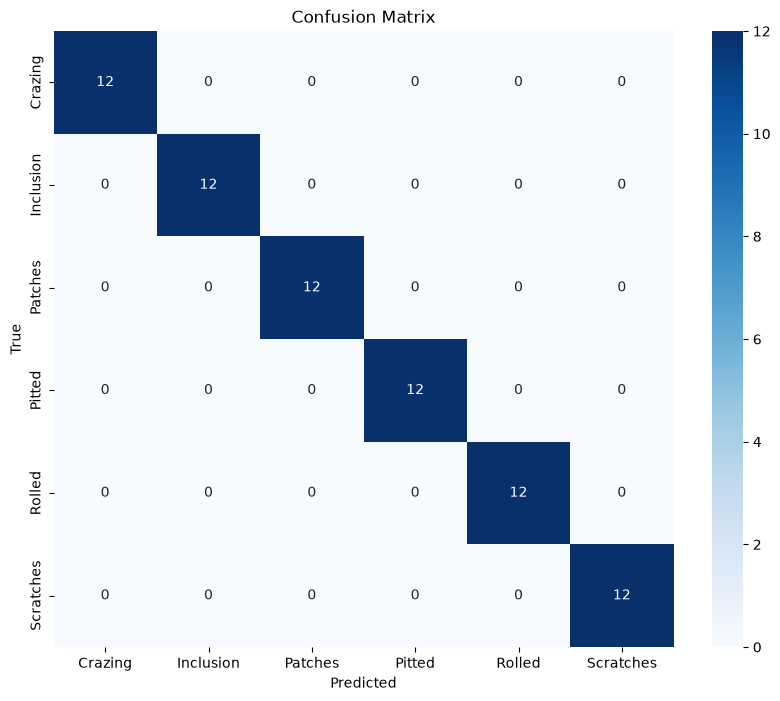

In [11]:
class_names = test_generator.class_indices.keys()

y_true = test_generator.classes
y_pred = np.argmax(model.predict(test_generator), axis=-1)

cm = confusion_matrix(y_true, y_pred)

plt.figure(figsize=(10, 8))
sns.heatmap(cm, annot=True, fmt='d', cmap='Blues',
            xticklabels=class_names, yticklabels=class_names)
plt.xlabel('Predicted')
plt.ylabel('True')
plt.title('Confusion Matrix')
plt.savefig(
    "results/confusion_matrix.png",
    dpi=300,
    bbox_inches="tight"
)
plt.show()

In [12]:
model.save("results/neu-metal-defect-mobilenetv2.keras")
class_indices = train_generator.class_indices

with open("results/class_indices.json", "w") as f:
    json.dump(class_indices, f, indent=4)